# Part 2: embedding vectors to trained classifiers

**Purpose**

Reads an embedding CSV produced by Part 1, trains lightweight task heads on the
frozen embeddings, and reports AUC with confidence intervals, an operating
point, and a signal check.

Runs on a laptop CPU in minutes. The expensive stage already happened in Part 1,
and this notebook can be re-run freely to try different heads and settings.

**Two modes, set in Section 1.**

| | `generic` | `replication` |
|---|---|---|
| Input | any embedding CSV | a CSV with a `subsets` column |
| Splits | random stratified, made here | predefined D1 to D4 and TEST |
| Use it for | a new finding, a new dataset | reproducing a published cohort |

**Optional paired comparison.** Point `COMPARE_CSV` at a second embedding file
covering the same studies and the notebook runs a paired DeLong test between the
two encoders on the identical test samples. This is how a backbone swap is
measured properly: same scans, same splits, same head, one variable changed.


## 1. Settings

The only cell that normally needs editing.


In [59]:
# IN:  nothing
# OUT: paths, settings, and a dedicated output folder for this run

from pathlib import Path
from datetime import datetime
import json, platform

NOTEBOOK_DIR = Path.cwd()

# ---- what to run ---------------------------------------------------------
MODE        = "replication"   # "generic" or "replication"
GRID_SEARCH = True           # False = fixed hyperparameters, about a minute
                              # True  = published grid, hours (see Section 4)
GRID_SPLITS = ["D3"]          # which splits to grid-search, ignored if GRID_SEARCH is False

# ---- inputs --------------------------------------------------------------
CSV_PATH      = NOTEBOOK_DIR / "embeddings_pillar0_rsna.csv"
COMPARE_CSV   = NOTEBOOK_DIR / "embeddings_google_rsna.csv"   # None to skip Section 9
BACKBONE_NAME = "Pillar-0"
COMPARE_NAME  = "Google CT Foundation"

# ---- evaluation ----------------------------------------------------------
LABEL_NAME   = "Central PE"   # for plot titles and the run name
VAL_FRACTION = 0.25           # generic mode only
SENSITIVITY  = 0.85           # minimum true positive rate the operating point must hit
N_BOOTSTRAP  = 2000
N_SHUFFLE    = 50
SEED         = 42

# ---- output folder, one per run -----------------------------------------
RUN_TAG  = "grid" if GRID_SEARCH else "fixed"
SLUG     = LABEL_NAME.lower().replace(" ", "-")
RUN_NAME = f"{datetime.now():%Y%m%d-%H%M%S}_{SLUG}_{MODE}_{RUN_TAG}"
RUN_DIR  = NOTEBOOK_DIR / "results" / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)

CONFIG = {
    "run_name": RUN_NAME,
    "started": datetime.now().isoformat(timespec="seconds"),
    "mode": MODE,
    "grid_search": GRID_SEARCH,
    "grid_splits": GRID_SPLITS if GRID_SEARCH else None,
    "backbone": BACKBONE_NAME,
    "compare_to": COMPARE_NAME if COMPARE_CSV else None,
    "embeddings_csv": str(CSV_PATH.name),
    "compare_csv": str(Path(COMPARE_CSV).name) if COMPARE_CSV else None,
    "label": LABEL_NAME,
    "sensitivity_target": SENSITIVITY,
    "val_fraction": VAL_FRACTION if MODE == "generic" else None,
    "n_bootstrap": N_BOOTSTRAP,
    "n_shuffle": N_SHUFFLE,
    "seed": SEED,
    "python": platform.python_version(),
    "platform": platform.platform(),
}

print("run    :", RUN_NAME)
print("output :", RUN_DIR)
print("csv    :", CSV_PATH.name, "| exists:", CSV_PATH.exists())
if COMPARE_CSV:
    print("compare:", Path(COMPARE_CSV).name, "| exists:", Path(COMPARE_CSV).exists())

run    : 20260728-140514_central-pe_replication_grid
output : /Users/peteryazdi/Desktop/P3/code/AI_Platform_kit/frozen_pillar-0/results/20260728-140514_central-pe_replication_grid
csv    : embeddings_pillar0_rsna.csv | exists: True
compare: embeddings_google_rsna.csv | exists: True


## 2. Load

The CSV contract between Part 1 and Part 2 is three columns:

| Column | Meaning |
|---|---|
| `labels` | 0 or 1 |
| `embedding` | the vector as a bracketed string |
| `file_name` | study identifier, used to align two encoders |

`subsets` and `orig_depth` are added by Part 1 and used where present.

The embedding is stored as text because a CSV cell holds one value. Parsing back
is a single `np.fromstring` call, which is how the reference pipeline reads it
too, so the format is unchanged from the published code.


In [60]:
# IN:  CSV_PATH
# OUT: X (n, d) embeddings, y (n,) labels, df the full table

import numpy as np, pandas as pd

def load_embeddings(path):
    d = pd.read_csv(path)
    X = np.array([np.fromstring(s[1:-1], sep=",") for s in d["embedding"]])
    return d, X, d["labels"].values.astype(int)

df, X, y = load_embeddings(CSV_PATH)

print(f"{len(df)} volumes | embedding dimension {X.shape[1]}")
print("labels:", pd.Series(y).value_counts().to_dict())
print("NaN:", int(np.isnan(X).sum()), "| all-zero rows:", int((X == 0).all(1).sum()))
if "orig_depth" in df:
    print("original depth min/median/max:", df.orig_depth.min(),
          int(df.orig_depth.median()), df.orig_depth.max())

956 volumes | embedding dimension 1152
labels: {0: 730, 1: 226}
NaN: 0 | all-zero rows: 0
original depth min/median/max: 135 232 256


## 3. Splits

**Replication mode** reads the `subsets` column, where each row lists which
predefined subsets a study belongs to. The subsets are nested training sets of
increasing size drawn from one training pool, all evaluated on the same fixed
test set:

| | Positives | Negatives | Question it answers |
|---|---|---|---|
| D1 | 32 | 32 | does more labelled data help |
| D2 | 64 | 64 | " |
| D3 | all | matched | " |
| D4 | all | all | does adding negatives help, and does imbalance hurt |
| TEST | fixed | fixed | never trained on |

D3 and D4 hold positives constant and vary only the negatives, so any difference
between them is attributable to the negatives alone.

**Generic mode** makes one stratified random split.

The assertion that training and test sets do not intersect is not decoration. A
single leaked study inflates every number downstream and is invisible in the
output.


In [61]:
# IN:  df, MODE
# OUT: splits, a dict of name -> (train mask, test mask)

from sklearn.model_selection import train_test_split

splits = {}

if MODE == "replication":
    assert "subsets" in df, "replication mode needs a subsets column"
    sub = df["subsets"].astype(str)
    te = sub.str.contains("TEST").values
    for tag in ["D1", "D2", "D3", "D4"]:
        tr = sub.str.contains(tag).values
        if tr.sum():
            splits[tag] = (tr, te)
else:
    idx = np.arange(len(y))
    tr_i, te_i = train_test_split(idx, test_size=VAL_FRACTION, stratify=y, random_state=SEED)
    tr = np.zeros(len(y), bool); tr[tr_i] = True
    te = np.zeros(len(y), bool); te[te_i] = True
    splits["all"] = (tr, te)

for name, (tr, te) in splits.items():
    assert not (tr & te).any(), f"{name}: train and test overlap"
    print(f"{name:5s} train {tr.sum():4d} ({int(y[tr].sum()):3d} pos) | "
          f"test {te.sum():4d} ({int(y[te].sum()):3d} pos)")

D1    train   64 ( 32 pos) | test  144 ( 36 pos)
D2    train  127 ( 63 pos) | test  144 ( 36 pos)
D3    train  392 (190 pos) | test  144 ( 36 pos)
D4    train  812 (190 pos) | test  144 ( 36 pos)


## 4. The task heads

Three heads, deliberately spanning a wide range of flexibility.

| Head | Flexibility | What it can represent |
|---|---|---|
| Linear probe | lowest | one straight boundary through the embedding space |
| Random forest | medium | many axis-aligned splits combined by vote |
| Neural network | highest | arbitrary curved boundaries |

**Why a tie between them is the interesting outcome.** If a straight line does as
well as a neural network, the finding is already linearly separable in the
embedding, which means the frozen encoder is doing the diagnostic work and the
head is only reading off an answer that is present. That is the core evidence for
the frozen-encoder approach: one expensive pass over the imaging data, then a
trivial head.

Class weighting is applied throughout so the imbalanced subsets train sensibly.

### Fixed hyperparameters or grid search

`GRID_SEARCH = False` fits one model per head with sensible fixed settings. Every
head takes a few seconds, so the whole notebook runs in about a minute.

`GRID_SEARCH = True` swaps in the published grid: 2700 random forest
combinations and 96 neural network combinations, each evaluated by 5-fold
cross-validation. That is roughly 14,000 model fits and takes hours.

**Which to use.** Fixed hyperparameters are correct for the backbone comparison,
because both encoders receive the identical head and neither can be favoured by
tuning. Grid search is needed only to match a published protocol exactly, which
matters when quoting a number alongside one from a paper.

Note the direction of the bias: a published figure produced by grid search
compared against a fixed-hyperparameter figure understates the fixed one, since
tuning would likely improve it. Erring in that direction is the safe way to be
wrong, but it does mean the protocols are not identical until the grid is run.

`GRID_SPLITS` limits the search to named splits, since running the full grid on
all four is rarely worth the wall time. The default is `["D3"]`, the largest
balanced set and the natural primary comparison.


In [62]:
# IN:  GRID_SEARCH, GRID_SPLITS
# OUT: build_heads (factories) and fit_score (fit and return test probabilities)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

def build_heads(seed=SEED):
    return {
        "linear probe": lambda: make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=5000, class_weight="balanced", random_state=seed)),
        "random forest": lambda: RandomForestClassifier(
            n_estimators=100, max_depth=7, min_samples_split=10, min_samples_leaf=5,
            max_features="sqrt", class_weight="balanced_subsample", random_state=seed),
        "neural network": lambda: make_pipeline(
            StandardScaler(),
            MLPClassifier(hidden_layer_sizes=(64, 64), alpha=1e-3, max_iter=800,
                          early_stopping=True, random_state=seed)),
    }

# Published grids. The random forest grid is 5 x 5 x 3 x 4 x 3 x 3 = 2700 fits,
# times 5 folds. The neural network grid is reduced from the published 250-trial
# random search to a 96-point grid so it finishes in comparable time.
GRIDS = {
    "random forest": (
        lambda seed: RandomForestClassifier(random_state=seed),
        {"n_estimators":     [50, 75, 100, 125, 150],
         "max_depth":        [3, 5, 7, 9, 11],
         "min_samples_split":[10, 15, 20],
         "min_samples_leaf": [5, 7, 10, 15],
         "max_features":     [0.3, 0.5, "sqrt"],
         "class_weight":     ["balanced", "balanced_subsample", {0: 1, 1: 3}]}),
    "neural network": (
        lambda seed: make_pipeline(StandardScaler(),
                                   MLPClassifier(max_iter=800, early_stopping=True,
                                                 random_state=seed)),
        {"mlpclassifier__hidden_layer_sizes": [(32, 32), (64, 64)],
         "mlpclassifier__alpha":              [1e-7, 1e-4, 1e-3],
         "mlpclassifier__learning_rate_init": [5e-4, 1e-3, 2e-3],
         "mlpclassifier__batch_size":         [32, 64]}),
    "linear probe": (
        lambda seed: make_pipeline(StandardScaler(),
                                   LogisticRegression(max_iter=5000,
                                                      class_weight="balanced",
                                                      random_state=seed)),
        {"logisticregression__C": [0.001, 0.01, 0.1, 1.0, 10.0]}),
}

_best = {}   # cache so a grid is searched once per (head, split, backbone)

def fit_score(make, Xtr, ytr, Xte, head=None, split=None, tag=""):
    """Fit a head and return predicted probabilities on the test set.

    Runs a grid search when GRID_SEARCH is on and this split is in GRID_SPLITS.
    Otherwise fits the fixed configuration. Selected parameters are cached and
    reported so the same head can be reused across encoders.
    """
    use_grid = (GRID_SEARCH and head in GRIDS
                and (split in GRID_SPLITS or GRID_SPLITS == "all"))
    if not use_grid:
        return make().fit(Xtr, ytr).predict_proba(Xte)[:, 1]

    key = (head, split, tag)
    if key not in _best:
        est, grid = GRIDS[head]
        gs = GridSearchCV(est(SEED), grid, scoring="roc_auc", n_jobs=-1,
                          cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
        gs.fit(Xtr, ytr)
        _best[key] = gs.best_estimator_
        print(f"    grid {head} / {split} {tag}: cv AUC {gs.best_score_:.3f} | {gs.best_params_}")
    return _best[key].fit(Xtr, ytr).predict_proba(Xte)[:, 1]

print("heads:", list(build_heads()))
if GRID_SEARCH:
    n = 2700 * 5
    print(f"GRID SEARCH ON for splits {GRID_SPLITS}. The random forest grid alone")
    print(f"is {n:,} fits per split per encoder. Expect hours, not minutes.")
else:
    print("grid search off, fixed hyperparameters, expect about a minute")

heads: ['linear probe', 'random forest', 'neural network']
GRID SEARCH ON for splits ['D3']. The random forest grid alone
is 13,500 fits per split per encoder. Expect hours, not minutes.


## 5. Metrics

**Bootstrap confidence interval.** The test set is resampled with replacement
and the AUC recomputed each time. The spread of those values is the uncertainty
in the estimate. A point estimate without an interval says nothing about whether
a difference is real.

**Operating point.** AUC summarises every possible threshold. Deployment needs
one. The threshold is chosen as the smallest value whose sensitivity reaches the
target, which maximises specificity subject to that constraint. Specificity at
that point is usually the number that decides whether a triage tool is usable,
because too many false alarms produce alert fatigue.

**Paired DeLong test.** When comparing two scorers on the same test samples,
their errors are correlated, and an unpaired test wastes that information.
DeLong's method computes the variance of the AUC difference from the structural
components of the Mann-Whitney statistic, paired by sample.


In [63]:
# IN:  nothing
# OUT: auc_ci, operating_point, delong_test

from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
from scipy import stats

rng_global = np.random.default_rng(SEED)

def auc_ci(y_true, score, n=N_BOOTSTRAP, seed=SEED):
    rng = np.random.default_rng(seed)
    point = roc_auc_score(y_true, score)
    vals = []
    for _ in range(n):
        i = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[i])) < 2:
            continue
        vals.append(roc_auc_score(y_true[i], score[i]))
    return point, float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))

def operating_point(y_true, score, target=SENSITIVITY):
    fpr, tpr, thr = roc_curve(y_true, score)
    ok = np.where(tpr >= target)[0]
    k = ok[0] if len(ok) else len(thr) - 1
    pred = (score >= thr[k]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"threshold": float(thr[k]),
            "sensitivity": tp / max(tp + fn, 1),
            "specificity": tn / max(tn + fp, 1),
            "tp": int(tp), "fp": int(fp), "tn": int(tn), "fn": int(fn)}

def _midrank(x):
    order = np.argsort(x); s = x[order]
    n = len(x); r = np.zeros(n); i = 0
    while i < n:
        j = i
        while j < n - 1 and s[j + 1] == s[i]:
            j += 1
        r[i:j + 1] = 0.5 * (i + j) + 1
        i = j + 1
    out = np.zeros(n); out[order] = r
    return out

def delong_test(y_true, s1, s2):
    """Paired DeLong test. Returns (auc1, auc2, p-value)."""
    pos, neg = s1[y_true == 1], s1[y_true == 0]
    m, n = len(pos), len(neg)
    S = np.vstack([s1, s2])
    Vp = np.zeros((2, m)); Vn = np.zeros((2, n)); A = np.zeros(2)
    for k in range(2):
        p, q = S[k][y_true == 1], S[k][y_true == 0]
        tz = _midrank(np.r_[p, q]); tp_, tq = _midrank(p), _midrank(q)
        A[k] = (tz[:m].sum() - m * (m + 1) / 2) / (m * n)
        Vp[k] = (tz[:m] - tp_) / n
        Vn[k] = 1.0 - (tz[m:] - tq) / m
    S10 = np.cov(Vp); S01 = np.cov(Vn)
    cov = S10 / m + S01 / n
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    if var <= 0:
        return A[0], A[1], 1.0
    z = (A[0] - A[1]) / np.sqrt(var)
    return A[0], A[1], float(2 * stats.norm.sf(abs(z)))

print("metrics ready")

metrics ready


## 6. Train and evaluate


In [64]:
# IN:  splits, X, y
# OUT: results, one row per (split, head), plus scores for the statistical tests

import time

results, scores = [], {}

for name, (tr, te) in splits.items():
    for head, make in build_heads().items():
        t0 = time.time()
        s = fit_score(make, X[tr], y[tr], X[te], head=head, split=name, tag=BACKBONE_NAME)
        a, lo, hi = auc_ci(y[te], s)
        op = operating_point(y[te], s)
        scores[(name, head)] = (y[te], s)
        results.append({"split": name, "head": head, "n_train": int(tr.sum()),
                        "auc": a, "lo": lo, "hi": hi,
                        "sens": op["sensitivity"], "spec": op["specificity"],
                        "grid": bool(GRID_SEARCH and name in GRID_SPLITS),
                        "seconds": time.time() - t0})

res = pd.DataFrame(results)
for r in res.itertuples():
    mark = " [grid]" if r.grid else ""
    print(f"{r.split:5s} {r.head:15s} n={r.n_train:4d}  AUC {r.auc:.3f} "
          f"({r.lo:.3f}, {r.hi:.3f})  sens {r.sens:.2f}  spec {r.spec:.2f}{mark}")

    grid linear probe / D3 Pillar-0: cv AUC 0.838 | {'logisticregression__C': 0.001}
    grid random forest / D3 Pillar-0: cv AUC 0.864 | {'class_weight': {0: 1, 1: 3}, 'max_depth': 7, 'max_features': 0.3, 'min_samples_leaf': 7, 'min_samples_split': 20, 'n_estimators': 75}
    grid neural network / D3 Pillar-0: cv AUC 0.832 | {'mlpclassifier__alpha': 0.001, 'mlpclassifier__batch_size': 32, 'mlpclassifier__hidden_layer_sizes': (32, 32), 'mlpclassifier__learning_rate_init': 0.002}
D1    linear probe    n=  64  AUC 0.753 (0.653, 0.846)  sens 0.86  spec 0.50
D1    random forest   n=  64  AUC 0.759 (0.663, 0.851)  sens 0.86  spec 0.43
D1    neural network  n=  64  AUC 0.594 (0.496, 0.689)  sens 0.86  spec 0.35
D2    linear probe    n= 127  AUC 0.834 (0.753, 0.904)  sens 0.86  spec 0.70
D2    random forest   n= 127  AUC 0.866 (0.800, 0.921)  sens 0.86  spec 0.71
D2    neural network  n= 127  AUC 0.588 (0.488, 0.697)  sens 0.86  spec 0.28
D3    linear probe    n= 392  AUC 0.900 (0.842, 0.947)

## 7. Are the heads distinguishable

Overlapping intervals suggest a tie but do not establish one. The paired DeLong
test is the direct answer, with Holm correction because three comparisons are
made within each split.


In [65]:
# IN:  scores
# OUT: pairwise head comparisons within each split

from itertools import combinations

rows = []
for name in splits:
    heads = list(build_heads())
    ps = []
    for h1, h2 in combinations(heads, 2):
        yt, s1 = scores[(name, h1)]
        _,  s2 = scores[(name, h2)]
        a1, a2, p = delong_test(yt, s1, s2)
        ps.append((h1, h2, a1 - a2, p))
    order = np.argsort([p for *_, p in ps])
    holm = np.zeros(len(ps))
    for rank, i in enumerate(order):
        holm[i] = min(1.0, ps[i][3] * (len(ps) - rank))
    holm = np.maximum.accumulate(holm[order])[np.argsort(order)]
    for (h1, h2, d, p), hp in zip(ps, holm):
        rows.append({"split": name, "pair": f"{h1} vs {h2}",
                     "delta_auc": d, "p": p, "p_holm": hp})

cmp_heads = pd.DataFrame(rows)
print(cmp_heads.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print("\nno p below 0.05 means the heads are statistically tied,")
print("which indicates the encoder rather than the head is doing the work")

split                            pair  delta_auc     p  p_holm
   D1   linear probe vs random forest     -0.006 0.861   0.861
   D1  linear probe vs neural network      0.159 0.001   0.002
   D1 random forest vs neural network      0.165 0.001   0.002
   D2   linear probe vs random forest     -0.033 0.380   0.380
   D2  linear probe vs neural network      0.245 0.000   0.000
   D2 random forest vs neural network      0.278 0.000   0.000
   D3   linear probe vs random forest     -0.008 0.717   0.717
   D3  linear probe vs neural network      0.018 0.229   0.687
   D3 random forest vs neural network      0.027 0.323   0.687
   D4   linear probe vs random forest      0.010 0.763   0.763
   D4  linear probe vs neural network     -0.028 0.374   0.748
   D4 random forest vs neural network     -0.038 0.138   0.414

no p below 0.05 means the heads are statistically tied,
which indicates the encoder rather than the head is doing the work


## 8. Signal check

With more embedding dimensions than training samples, a flexible model can
separate almost any labelling by chance, so a strong score is not by itself
evidence of anything. Shuffling the training labels destroys any true
relationship while leaving everything else identical. If the real result sits
far outside the shuffled range, the signal is genuine.

The second check tests whether scan coverage predicts the label on its own.
Volumes shorter than 256 slices are padded, and if padding correlated with the
outcome the classifier could be reading acquisition protocol rather than
anatomy.


In [66]:
# IN:  the largest split
# OUT: SIGNAL, a dict recorded in the run manifest

big = max(splits, key=lambda k: splits[k][0].sum())
tr, te = splits[big]
make = build_heads()["linear probe"]

real = roc_auc_score(y[te], make().fit(X[tr], y[tr]).predict_proba(X[te])[:, 1])
rng = np.random.default_rng(SEED)
null = [roc_auc_score(y[te],
                      make().fit(X[tr], rng.permutation(y[tr])).predict_proba(X[te])[:, 1])
        for _ in range(N_SHUFFLE)]

depth_auc = None
if "orig_depth" in df:
    depth_auc = float(roc_auc_score(y[te], df.orig_depth.values[te].astype(float)))

SIGNAL = {"split": big, "real": float(real),
          "shuffled_mean": float(np.mean(null)), "shuffled_max": float(np.max(null)),
          "n_shuffle": N_SHUFFLE,
          "verdict": "signal is real" if real > np.max(null) else "NOT SEPARATED FROM CHANCE",
          "depth_alone_auc": depth_auc}

print(f"split {big}")
print(f"  real result     : {SIGNAL['real']:.3f}")
print(f"  shuffled labels : mean {SIGNAL['shuffled_mean']:.3f}, "
      f"max {SIGNAL['shuffled_max']:.3f} over {N_SHUFFLE} runs")
print(f"  verdict         : {SIGNAL['verdict']}")
if depth_auc is not None:
    print(f"  scan depth alone: AUC {depth_auc:.3f} (0.5 = no confound)")

split D4
  real result     : 0.898
  shuffled labels : mean 0.502, max 0.658 over 50 runs
  verdict         : signal is real
  scan depth alone: AUC 0.535 (0.5 = no confound)


## 9. Backbone comparison

Only runs if `COMPARE_CSV` is set. Studies are aligned on `file_name`, so the two
encoders are evaluated on exactly the same test samples with the same head and
the same splits. That makes the comparison paired, and the DeLong test uses the
correlation between the two scorers rather than discarding it.

This is the controlled experiment a backbone swap calls for. Comparing a number
computed here against a number printed in a paper is not the same thing, because
preprocessing, head configuration and evaluation protocol all differ.


In [67]:
# IN:  COMPARE_CSV
# OUT: paired comparison of the two encoders, every head, on identical studies

if COMPARE_CSV is None:
    print("COMPARE_CSV not set, skipping")
else:
    df2, X2, y2 = load_embeddings(COMPARE_CSV)
    key = "file_name" if "file_name" in df2 else "series_id"

    common = sorted(set(df.file_name) & set(df2[key]))
    print(f"{BACKBONE_NAME}: {len(df)} dim {X.shape[1]} | "
          f"{COMPARE_NAME}: {len(df2)} dim {X2.shape[1]} | overlap: {len(common)}")

    i1 = df.set_index("file_name").index.get_indexer(common)
    i2 = df2.set_index(key).index.get_indexer(common)
    assert (y[i1] == y2[i2]).all(), "labels disagree between the two files"

    sub = df["subsets"].astype(str).values[i1] if "subsets" in df else np.array([""] * len(common))
    te  = np.array(["TEST" in s for s in sub]) if MODE == "replication" else None

    out = []
    for head in build_heads():
        for name in splits:
            tr = np.array([name in s for s in sub])
            t  = te if te is not None else ~tr
            if tr.sum() == 0 or t.sum() == 0:
                continue
            make = build_heads()[head]
            # each encoder gets its own grid search, so neither is handicapped
            s1 = fit_score(make, X[i1][tr],  y[i1][tr],  X[i1][t],
                           head=head, split=name, tag=BACKBONE_NAME)
            s2 = fit_score(make, X2[i2][tr], y2[i2][tr], X2[i2][t],
                           head=head, split=name, tag=COMPARE_NAME)
            a1, a2, p = delong_test(y[i1][t], s1, s2)
            out.append({"head": head, "split": name,
                        BACKBONE_NAME: a1, COMPARE_NAME: a2,
                        "delta": a1 - a2, "delong_p": p,
                        "grid": bool(GRID_SEARCH and name in GRID_SPLITS)})

    comp = pd.DataFrame(out)

    # Holm correction across every comparison made here
    o = np.argsort(comp.delong_p.values)
    holm = np.zeros(len(comp))
    for rank, i in enumerate(o):
        holm[i] = min(1.0, comp.delong_p.values[i] * (len(comp) - rank))
    comp["p_holm"] = np.maximum.accumulate(holm[o])[np.argsort(o)]

    for head in comp["head"].unique():
        print(f"\n{head}")
        s = comp[comp["head"] == head]
        print(s[["split", BACKBONE_NAME, COMPARE_NAME, "delta", "delong_p", "p_holm"]]
              .to_string(index=False, float_format=lambda v: f"{v:.3f}"))

    print(f"\ndelta positive means {BACKBONE_NAME} scores higher")
    print("a consistent sign across all three heads means the result is not")
    print("an artefact of one head choice")
    # saved to the run folder in Section 11

Pillar-0: 956 dim 1152 | Google CT Foundation: 956 dim 1408 | overlap: 956
    grid linear probe / D3 Google CT Foundation: cv AUC 0.699 | {'logisticregression__C': 0.01}
    grid random forest / D3 Google CT Foundation: cv AUC 0.750 | {'class_weight': {0: 1, 1: 3}, 'max_depth': 7, 'max_features': 0.3, 'min_samples_leaf': 7, 'min_samples_split': 10, 'n_estimators': 50}
    grid neural network / D3 Google CT Foundation: cv AUC 0.702 | {'mlpclassifier__alpha': 0.0001, 'mlpclassifier__batch_size': 32, 'mlpclassifier__hidden_layer_sizes': (64, 64), 'mlpclassifier__learning_rate_init': 0.001}

linear probe
split  Pillar-0  Google CT Foundation  delta  delong_p  p_holm
   D1     0.753                 0.533  0.220     0.001   0.013
   D2     0.834                 0.698  0.136     0.014   0.084
   D3     0.900                 0.781  0.119     0.002   0.020
   D4     0.898                 0.785  0.113     0.023   0.117

random forest
split  Pillar-0  Google CT Foundation  delta  delong_p  p_hol

## 10. Plots


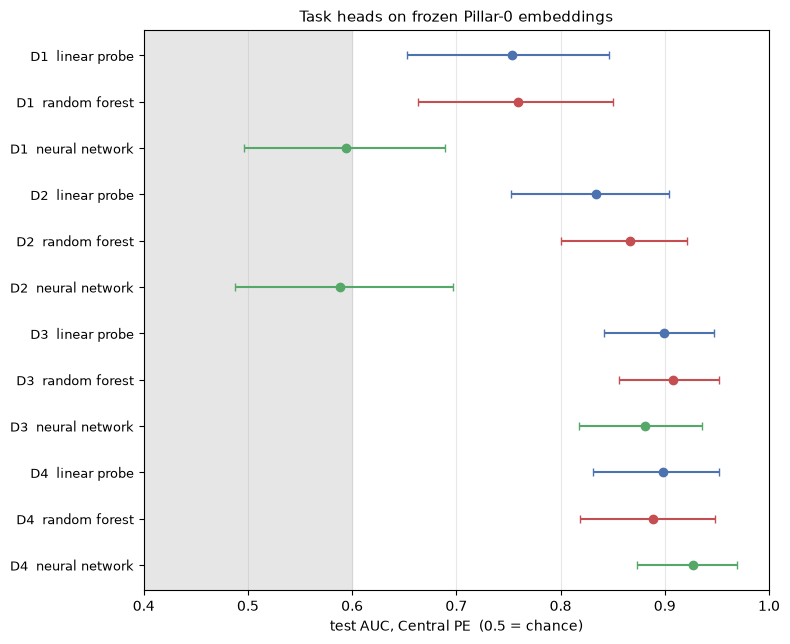

In [68]:
# IN:  res
# OUT: fig_auc_by_head.png in RUN_DIR

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 0.42 * len(res) + 1.5))
colors = {"linear probe": "#4c72b0", "random forest": "#c44e52", "neural network": "#55a868"}
lab, ypos = [], []
for i, r in enumerate(res.itertuples()):
    ax.errorbar(r.auc, i, xerr=[[r.auc - r.lo], [r.hi - r.auc]],
                fmt="o", color=colors.get(r.head, "gray"), capsize=3)
    lab.append(f"{r.split}  {r.head}"); ypos.append(i)

ax.axvspan(0.4, 0.6, color="0.9", zorder=0)
ax.set_yticks(ypos); ax.set_yticklabels(lab, fontsize=9)
ax.set_xlim(0.4, 1.0); ax.set_xlabel(f"test AUC, {LABEL_NAME}  (0.5 = chance)")
ax.set_title(f"Task heads on frozen {BACKBONE_NAME} embeddings", fontsize=11)
ax.invert_yaxis(); ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(RUN_DIR / "fig_auc_by_head.png", dpi=150)
plt.show()

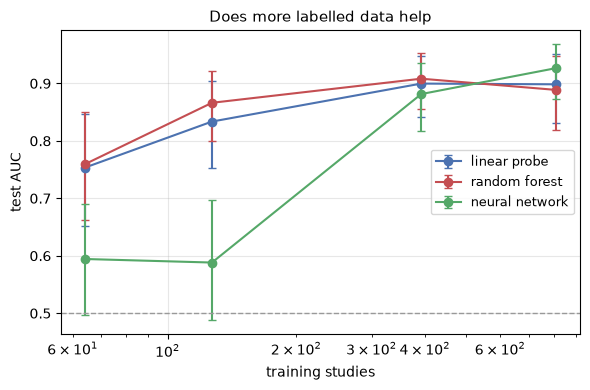

In [69]:
# IN:  res
# OUT: fig_scaling.png in RUN_DIR, replication mode only

if MODE == "replication" and len(res["split"].unique()) > 1:
    fig, ax = plt.subplots(figsize=(6, 4))
    for head in res["head"].unique():
        s = res[res["head"] == head].sort_values("n_train")
        ax.errorbar(s.n_train, s.auc, yerr=[s.auc - s.lo, s.hi - s.auc],
                    marker="o", capsize=3, label=head, color=colors.get(head, "gray"))
    ax.set_xscale("log")
    ax.set_xlabel("training studies"); ax.set_ylabel("test AUC")
    ax.set_title("Does more labelled data help", fontsize=11)
    ax.axhline(0.5, ls="--", c="0.6", lw=1)
    ax.legend(fontsize=9); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(RUN_DIR / "fig_scaling.png", dpi=150)
    plt.show()
else:
    print("scaling plot needs replication mode with multiple splits")

## 11. Save

Everything from this run goes into its own folder under `results/`, named by
timestamp, label, mode and whether the grid search was used. Nothing is
overwritten, and every file is traceable to the settings that produced it.

```
results/20260728-140312_central-pe_replication_fixed/
├── run_config.json           every setting, plus dataset shape and environment
├── metrics.csv               AUC, CI, sensitivity, specificity per split and head
├── head_comparisons.csv      DeLong between heads, within each split
├── comparison_backbones.csv  DeLong between encoders, if COMPARE_CSV was set
├── best_params.json          selected hyperparameters, grid runs only
├── fig_auc_by_head.png
├── fig_scaling.png
└── summary.txt               the headline numbers as plain text
```

`run_config.json` is the file that makes a run reproducible six months later. It
records not only the settings but the row counts and embedding dimension
actually loaded, so a changed input file is detectable.


In [70]:
# IN:  everything computed above
# OUT: RUN_DIR populated with results, figures and a manifest

import json

CONFIG.update({
    "finished": datetime.now().isoformat(timespec="seconds"),
    "n_volumes": int(len(df)),
    "embedding_dim": int(X.shape[1]),
    "label_counts": {str(k): int(v) for k, v in pd.Series(y).value_counts().items()},
    "splits": {k: {"n_train": int(tr.sum()), "n_train_pos": int(y[tr].sum()),
                   "n_test": int(te.sum()), "n_test_pos": int(y[te].sum())}
               for k, (tr, te) in splits.items()},
    "signal_check": SIGNAL,
})
if COMPARE_CSV:
    CONFIG["compare_dim"] = int(X2.shape[1])
    CONFIG["compare_overlap"] = int(len(common))

(RUN_DIR / "run_config.json").write_text(json.dumps(CONFIG, indent=2))
res.to_csv(RUN_DIR / "metrics.csv", index=False)
cmp_heads.to_csv(RUN_DIR / "head_comparisons.csv", index=False)

if COMPARE_CSV:
    comp.to_csv(RUN_DIR / "comparison_backbones.csv", index=False)

if GRID_SEARCH and _best:
    params = {f"{h} | {s} | {t}": getattr(m, "get_params", lambda: {})()
              for (h, s, t), m in _best.items()}
    params = {k: {kk: str(vv) for kk, vv in v.items() if "__" in kk or "_" not in kk[:1]}
              for k, v in params.items()}
    (RUN_DIR / "best_params.json").write_text(json.dumps(params, indent=2, default=str))

# plain-text summary, the thing you actually paste into a message
lines = [f"run: {RUN_NAME}", f"{len(df)} volumes, {X.shape[1]}-dim {BACKBONE_NAME} embeddings",
         f"hyperparameters: {'published grid on ' + str(GRID_SPLITS) if GRID_SEARCH else 'fixed'}", ""]
for r in res.itertuples():
    lines.append(f"{r.split:5s} {r.head:15s} n={r.n_train:4d}  AUC {r.auc:.3f} "
                 f"({r.lo:.3f}, {r.hi:.3f})  sens {r.sens:.2f}  spec {r.spec:.2f}")
if COMPARE_CSV:
    lines += ["", f"paired comparison against {COMPARE_NAME}:"]
    for r in comp.itertuples():
        lines.append(f"{r.head:15s} {r.split:5s}  delta {r.delta:+.3f}  "
                     f"p {r.delong_p:.4f}  holm {r.p_holm:.4f}")
lines += ["", f"signal check: real {SIGNAL['real']:.3f} vs shuffled max "
              f"{SIGNAL['shuffled_max']:.3f} ({SIGNAL['verdict']})"]
(RUN_DIR / "summary.txt").write_text("\n".join(lines))

print("\n".join(lines))
print("\nsaved to:", RUN_DIR)
for f in sorted(RUN_DIR.iterdir()):
    print("  ", f.name)

run: 20260728-140514_central-pe_replication_grid
956 volumes, 1152-dim Pillar-0 embeddings
hyperparameters: published grid on ['D3']

D1    linear probe    n=  64  AUC 0.753 (0.653, 0.846)  sens 0.86  spec 0.50
D1    random forest   n=  64  AUC 0.759 (0.663, 0.851)  sens 0.86  spec 0.43
D1    neural network  n=  64  AUC 0.594 (0.496, 0.689)  sens 0.86  spec 0.35
D2    linear probe    n= 127  AUC 0.834 (0.753, 0.904)  sens 0.86  spec 0.70
D2    random forest   n= 127  AUC 0.866 (0.800, 0.921)  sens 0.86  spec 0.71
D2    neural network  n= 127  AUC 0.588 (0.488, 0.697)  sens 0.86  spec 0.28
D3    linear probe    n= 392  AUC 0.900 (0.842, 0.947)  sens 0.86  spec 0.76
D3    random forest   n= 392  AUC 0.908 (0.856, 0.952)  sens 0.86  spec 0.71
D3    neural network  n= 392  AUC 0.881 (0.817, 0.935)  sens 0.86  spec 0.70
D4    linear probe    n= 812  AUC 0.898 (0.832, 0.952)  sens 0.86  spec 0.81
D4    random forest   n= 812  AUC 0.889 (0.819, 0.948)  sens 0.86  spec 0.76
D4    neural networ

## 12. Reading the result

**The heads tie.** Expected, and informative. It means the finding is linearly
separable in the embedding, so the encoder is doing the diagnostic work.

**AUC rises with training size.** Expected. A flat curve at low AUC suggests the
finding is not represented in the embedding at all. A curve that plateaus early
suggests more labels will not help and the limit is the encoder.

**Specificity at the operating point matters more than AUC for deployment.** A
model with good AUC and poor specificity at a clinically required sensitivity
generates enough false alarms to cause alert fatigue, which stops adoption
regardless of how the summary statistic looks.

**What this is not.** A single-site result. Embeddings encode scanner and
protocol characteristics alongside anatomy, so performance at a second
institution is expected to drop and must be measured before any claim
generalises. Report-derived labels also carry noise, which bounds achievable
performance.
